# Neural networks

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://githubtocolab.com/EnriqueVilchezL/machine-learning/blob/main/book/06-deep-learning/neural-networks/neural-networks-notebook.ipynb)

Companion notebook for the *Neural networks* slides. Each idea is written first by hand
with NumPy, in small classes shaped like PyTorch's, and then with the PyTorch module that does the same job.

**Data:** the two moons (300 synthetic points, 2 features, 2 classes) and, for several classes,
the Digits data (1 797 images of 8 × 8 pixels, 10 digits).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from sklearn.datasets import load_digits, make_moons
from sklearn.model_selection import train_test_split
from torch import nn

RANDOM_STATE = 42
HIDDEN_UNITS = 10
LEARNING_RATE = 0.5
STEPS = 3000
DIGIT_STEPS = 300

torch.manual_seed(RANDOM_STATE)
torch.set_default_dtype(torch.float64)
rng = np.random.default_rng(RANDOM_STATE)

X, y = make_moons(n_samples=300, noise=0.25, random_state=RANDOM_STATE)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3,
                                                    random_state=RANDOM_STATE, stratify=y)
Y_train = y_train[:, None].astype(float)  # one column, like the network's output
X_train_t = torch.tensor(X_train)
X_test_t = torch.tensor(X_test)
Y_train_t = torch.tensor(Y_train)

## 1. The artificial neuron

A weighted sum plus a bias, bent by an activation: $z = \mathbf{w}^\top \mathbf{x} + b$, $a = g(z)$.
With the sigmoid $\sigma(z) = \dfrac{1}{1 + e^{-z}}$ this is the example of the slides.
In PyTorch the weighted sum is an `nn.Linear` layer; its weights are set by hand inside `torch.no_grad()`.

In [2]:
x_example = np.array([1.0, 2.0, -1.0])
w_example = np.array([0.8, 0.2, -0.5])
b_example = -0.3
z = w_example @ x_example + b_example  # z = w^T x + b
a_by_hand = 1 / (1 + np.exp(-z))       # a = sigma(z)

neuron = nn.Linear(3, 1)
with torch.no_grad():
    neuron.weight.copy_(torch.tensor(w_example[None, :]))
    neuron.bias.fill_(b_example)
z_torch = neuron(torch.tensor(x_example))
a_torch = torch.sigmoid(z_torch)
same = np.allclose(a_by_hand, a_torch.detach().numpy())
print(f"z = {z:.2f}, a = {a_by_hand:.3f} | same result:", same)

z = 1.40, a = 0.802 | same result: True


## 2. The forward pass

Each layer computes $\mathbf{a}^{(l)} = g(\mathbf{W}^{(l)} \mathbf{a}^{(l-1)} + \mathbf{b}^{(l)})$, starting from $\mathbf{a}^{(0)} = \mathbf{x}$.
The NumPy classes below copy PyTorch's design: a `Linear` layer keeps $\mathbf{W}^{(l)}$ in `weight`
(one row per output) and $\mathbf{b}^{(l)}$ in `bias`, each a `Parameter` with a `.grad` slot;
`Sequential` chains the layers. Rows are examples, so a whole table goes through as `A @ W.T + b`.
The `backward` methods are explained in section 4.

In [3]:
class Parameter:
    """An array plus a slot for its gradient."""

    def __init__(self, data: np.ndarray):
        self.data = data
        self.grad = np.zeros_like(data)


class Module:
    """Calling a module runs its forward pass."""

    def __call__(self, x: np.ndarray) -> np.ndarray:
        return self.forward(x)

    def parameters(self) -> list:
        return []


class Linear(Module):
    """z = a W^T + b, with W shaped (out, in) and the same random start as nn.Linear."""

    def __init__(self, in_features: int, out_features: int):
        bound = 1 / np.sqrt(in_features)
        self.weight = Parameter(rng.uniform(-bound, bound, (out_features, in_features)))
        self.bias = Parameter(rng.uniform(-bound, bound, out_features))

    def forward(self, a):
        self.a = a
        return a @ self.weight.data.T + self.bias.data

    def backward(self, delta):
        self.weight.grad += delta.T @ self.a  # delta^(l) (a^(l-1))^T
        self.bias.grad += delta.sum(axis=0)
        return delta @ self.weight.data       # (W^(l))^T delta^(l), sent to the layer below

    def parameters(self):
        return [self.weight, self.bias]


class ReLU(Module):
    """max(0, z), remembering where it was positive."""

    def forward(self, z):
        self.positive = z > 0
        return z * self.positive

    def backward(self, delta):
        return delta * self.positive  # times g'(z): 1 where z > 0, else 0


class Sequential(Module):
    """Run the layers in order, and backward in reverse order."""

    def __init__(self, *layers):
        self.layers = layers

    def forward(self, x):
        for layer in self.layers:
            x = layer(x)
        return x

    def backward(self, delta):
        for layer in reversed(self.layers):
            delta = layer.backward(delta)
        return delta

    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]


def sigmoid(z: np.ndarray) -> np.ndarray:
    return 1 / (1 + np.exp(-z))


def copy_weights(numpy_model: Module, torch_model: nn.Module) -> None:
    """Put the NumPy weights into the matching torch parameters."""
    with torch.no_grad():
        for mine, theirs in zip(numpy_model.parameters(), torch_model.parameters()):
            theirs.copy_(torch.from_numpy(mine.data))

The same network in both libraries: a ReLU hidden layer and one output score $z$.
The sigmoid is applied outside the network, because the loss of section 4 takes the score directly.

In [4]:
model = Sequential(Linear(2, HIDDEN_UNITS), ReLU(), Linear(HIDDEN_UNITS, 1))
net = nn.Sequential(nn.Linear(2, HIDDEN_UNITS), nn.ReLU(), nn.Linear(HIDDEN_UNITS, 1))
copy_weights(model, net)

p_by_hand = sigmoid(model(X_test))
p_torch = torch.sigmoid(net(X_test_t))
print("same result:", np.allclose(p_by_hand, p_torch.detach().numpy()))

same result: True


## 3. Softmax output for several classes

For $K$ classes the last layer gives $K$ scores and softmax turns them into probabilities: $\hat{y}_k = \dfrac{e^{z_k}}{\sum_{j} e^{z_j}}$.
The cost is the cross-entropy $-\frac{1}{n}\sum_i \log \hat{y}_{i, y_i}$. `nn.CrossEntropyLoss` takes the scores and applies softmax inside.

In [5]:
X_digits, y_digits = load_digits(return_X_y=True)
Xd_train, Xd_test, yd_train, yd_test = train_test_split(X_digits / 16, y_digits, test_size=0.3,
                                                        random_state=RANDOM_STATE, stratify=y_digits)
Xd_train_t, Xd_test_t = torch.tensor(Xd_train), torch.tensor(Xd_test)
yd_train_t, yd_test_t = torch.tensor(yd_train), torch.tensor(yd_test)

digits_model = Sequential(Linear(64, 32), ReLU(), Linear(32, 10))
digits_net = nn.Sequential(nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, 10))
copy_weights(digits_model, digits_net)

scores = digits_model(Xd_test)                            # z, one row of K scores per example
exp_scores = np.exp(scores)                               # e^{z_k}
probs_by_hand = exp_scores / exp_scores.sum(axis=1, keepdims=True)  # e^{z_k} / sum_j e^{z_j}
prob_true_class = probs_by_hand[np.arange(len(yd_test)), yd_test]   # y_hat_{i, y_i}
cost_by_hand = -np.mean(np.log(prob_true_class))

scores_t = digits_net(Xd_test_t)
probs_torch = torch.softmax(scores_t, dim=1)
cost_torch = nn.CrossEntropyLoss()(scores_t, yd_test_t)
print("same probabilities:", np.allclose(probs_by_hand, probs_torch.detach().numpy()))
print("same cost:", np.isclose(cost_by_hand, cost_torch.item()))

same probabilities: True
same cost: True


## 4. Cost and backpropagation

For two classes the cost is the mean cross-entropy $J = -\frac{1}{n}\sum_i \big[y_i \log \hat{y}_i + (1 - y_i)\log(1 - \hat{y}_i)\big]$.
Backpropagation starts from $\boldsymbol{\delta}^{(L)} = \hat{\mathbf{y}} - \mathbf{y}$, sends it back with
$\boldsymbol{\delta}^{(l)} = (\mathbf{W}^{(l+1)})^\top \boldsymbol{\delta}^{(l+1)} \odot g'(\mathbf{z}^{(l)})$,
and each gradient is $\boldsymbol{\delta}^{(l)} (\mathbf{a}^{(l-1)})^\top$: this is what each `backward` method does.
In PyTorch, `nn.BCEWithLogitsLoss` is this cost on the score $z$, and `loss.backward()` fills every `.grad` (autograd).

In [6]:
class BCEWithLogitsLoss:
    """Mean cross-entropy of sigmoid(z); backward gives delta^(L)."""

    def __call__(self, z, y):
        self.y = y
        self.p = sigmoid(z)  # y_hat
        losses = y * np.log(self.p) + (1 - y) * np.log(1 - self.p)
        return -np.mean(losses)

    def backward(self):
        return (self.p - self.y) / len(self.y)  # (y_hat - y), averaged over the n examples


loss_fn = BCEWithLogitsLoss()
z = model(X_train)
cost_by_hand = loss_fn(z, Y_train)
delta_L = loss_fn.backward()  # delta^(L)
model.backward(delta_L)

torch_loss_fn = nn.BCEWithLogitsLoss()
prediction = net(X_train_t)
loss = torch_loss_fn(prediction, Y_train_t)
loss.backward()
same_gradients = all(np.allclose(mine.grad, theirs.grad.numpy())
                     for mine, theirs in zip(model.parameters(), net.parameters()))
print("same cost:", np.isclose(cost_by_hand, loss.item()))
print("same gradients:", same_gradients)

same cost: True
same gradients: True


## 5. Gradient descent

Each step moves every parameter downhill: $\boldsymbol{\theta} \leftarrow \boldsymbol{\theta} - \alpha \, \nabla_{\boldsymbol{\theta}} J$.
Gradients add up in `.grad`, so each step first sets them to zero. The NumPy `SGD` has the same two methods as `torch.optim.SGD`,
and both loops are written the same way. From the same start they end with the same weights.

In [7]:
class SGD:
    """theta <- theta - lr * gradient, for every parameter."""

    def __init__(self, params: list, lr: float):
        self.params = params
        self.lr = lr

    def zero_grad(self):
        for p in self.params:
            p.grad = np.zeros_like(p.data)

    def step(self):
        for p in self.params:
            p.data = p.data - self.lr * p.grad


optimizer = SGD(model.parameters(), lr=LEARNING_RATE)
costs = []
for _ in range(STEPS):
    optimizer.zero_grad()
    z = model(X_train)
    cost = loss_fn(z, Y_train)
    model.backward(loss_fn.backward())
    optimizer.step()
    costs.append(cost)

torch_optimizer = torch.optim.SGD(net.parameters(), lr=LEARNING_RATE)
for _ in range(STEPS):
    torch_optimizer.zero_grad()
    prediction = net(X_train_t)
    loss = torch_loss_fn(prediction, Y_train_t)
    loss.backward()
    torch_optimizer.step()

same_weights = all(np.allclose(mine.data, theirs.detach().numpy())
                   for mine, theirs in zip(model.parameters(), net.parameters()))
print("same weights:", same_weights)

same weights: True


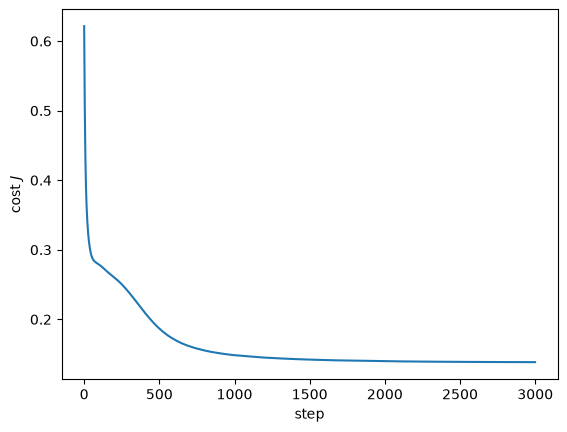

test accuracy 0.911


In [8]:
plt.plot(costs)
plt.xlabel("step")
plt.ylabel("cost $J$")
plt.show()

with torch.no_grad():
    predictions = (net(X_test_t) > 0).numpy().ravel()
print(f"test accuracy {np.mean(predictions == y_test):.3f}")

## 6. Training with an optimizer

The usual PyTorch recipe for the digits: `nn.CrossEntropyLoss` and `torch.optim.Adam`, an optimizer that
adapts the step size of each weight. The loop has the same four lines as in section 5.

In [9]:
optimizer = torch.optim.Adam(digits_net.parameters(), lr=0.01)
cross_entropy = nn.CrossEntropyLoss()
for _ in range(DIGIT_STEPS):
    optimizer.zero_grad()
    prediction = digits_net(Xd_train_t)
    loss = cross_entropy(prediction, yd_train_t)
    loss.backward()
    optimizer.step()

with torch.no_grad():
    predicted_digits = digits_net(Xd_test_t).argmax(dim=1)
accuracy = (predicted_digits == yd_test_t).double().mean().item()
print(f"training cost {loss.item():.3f}, test accuracy {accuracy:.3f}")

training cost 0.005, test accuracy 0.972


## Exercises

1. Build the XOR network of the slides with two `nn.Linear` layers (copy its weights inside `torch.no_grad()`)
   and the step activation `torch.heaviside`, and check its output on the four inputs.
2. In section 5, change `HIDDEN_UNITS` to 2 and to 50. How do the cost curve and the test accuracy change?
3. Write a NumPy `Tanh` module ($\tanh' = 1 - \tanh^2$), use it instead of `ReLU` together with `nn.Tanh()`,
   and run the gradient check of section 4 again.